# Targeted design: a worked example

A kinetic model has four parameters. The experimental budget is small. The
question the plant engineer asks is narrower than "what are the parameters":
**what yield will the reactor give at its operating point, and when should the
batch be stopped?** This notebook builds a campaign around that question with
the targeted-design tools in `discopt.doe` (see {doc}`../targeted-design` for
the theory) and measures what it buys.

We will

1. design the next runs for the plant yield, for the time of maximum yield, and
   for the activation energies, and compare them with a D-optimal design;
2. *certify* how close each design is to the best possible;
3. combine goals with tolerances;
4. run a sequential campaign that stops as soon as the yield is known well
   enough, against a D-optimal campaign on the same budget;
5. check robustness to a wrong parameter guess; and
6. do the same thing from the command line.

## The model

Consecutive first-order reactions $A \to B \to C$ with Arrhenius rate constants

$$k_i(T) = \exp\!\left(\ln k_i - \frac{E_i}{R}\Big(\frac1T - \frac1{T_\mathrm{ref}}\Big)\right),
\qquad
B(T, t) = \frac{k_1}{k_2 - k_1}\left(e^{-k_1 t} - e^{-k_2 t}\right),$$

with $A_0 = 1$, $T_\mathrm{ref} = 350$ K and $E_i$ in kJ/mol. The parameters are
$\theta = (\ln k_1, E_1, \ln k_2, E_2)$. We measure the intermediate $B$
($\sigma = 0.01$) at a temperature $T \in [320, 380]$ K and a time
$t \in [0.2, 10]$ h of our choosing. The plant runs at $T = 365$ K for 4 h.

In [1]:
import os
import shutil
import subprocess
import sys
import warnings
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")
warnings.simplefilter("ignore")

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discopt.doe import (
    SymbolicModel,
    Target,
    approximate_targeted_design,
    batch_optimal_experiment,
    certify_design,
    compute_fim,
    profile_target,
    robust_optimal_experiment,
    sequential_doe,
)
from discopt.doe.runs import campaign_experiment, symbolic_experiment

T_REF, R = 350.0, 8.314e-3  # K, kJ/(mol K)


def rate(i: int) -> str:
    return f"exp(lnk{i} - E{i}/{R}*(1/T - 1/{T_REF}))"


source = f"{rate(1)}/({rate(2)} - {rate(1)})*(exp(-{rate(1)}*t) - exp(-{rate(2)}*t))"
model = SymbolicModel(
    source=source,
    parameter_names=("lnk1", "E1", "lnk2", "E2"),
    input_names=("T", "t"),
    response_name="B",
    measurement_error=0.01,
)
bounds = {"T": (320.0, 380.0), "t": (0.2, 10.0)}
experiment = symbolic_experiment(model, input_bounds=bounds)

truth = {"lnk1": np.log(0.5), "E1": 60.0, "lnk2": np.log(0.2), "E2": 90.0}  # hidden
guess = {"lnk1": np.log(0.4), "E1": 50.0, "lnk2": np.log(0.25), "E2": 80.0}
plant = {"T": 365.0, "t": 4.0}
print(f"true yield at the plant point: {model.predict(truth, plant):.4f}")
print(f"predicted from the guess:      {model.predict(guess, plant):.4f}")

true yield at the plant point: 0.1243
predicted from the guess:      0.1365


## What three screening runs tell us

Three runs have been made. Their information matrix has rank 3, not 4: one
combination of the parameters is not identified yet. The yield at the plant
point is one of the things it does not identify, so its standard error is
infinite. Two more runs are in the budget.

In [2]:
initial = [{"T": 330.0, "t": 2.0}, {"T": 350.0, "t": 5.0}, {"T": 370.0, "t": 1.0}]
prior = sum(compute_fim(experiment, guess, d).fim for d in initial)
print("rank of the FIM after 3 runs:", np.linalg.matrix_rank(prior))

yield_at_plant = Target.responses(at=[plant])
print(yield_at_plant.resolve(experiment, guess).precision(prior).summary())

rank of the FIM after 3 runs: 3
Target precision (NOT estimable)
  SE(B) = inf


## Four ways to spend two runs

We design the two runs four ways.

* **D-optimal**: shrink the confidence region of all four parameters.
* **Plant yield**: `Target.responses(at=[plant])`, minimizing the variance of
  the predicted $B$ at 365 K, 4 h.
* **Time of maximum yield** at the plant temperature,
  $t^* = \ln(k_2/k_1)/(k_2 - k_1)$: a function of the parameters, given to
  `Target.function` in `jax.numpy`.
* **Activation energies**: `Target.parameters(["E1", "E2"])` with the
  determinant criterion ($D_s$). The rate constants at $T_\mathrm{ref}$ are
  nuisance parameters.

Each design is then judged on all three questions.

In [3]:
def k_at(th, i, T):
    return jnp.exp(th[f"lnk{i}"] - th[f"E{i}"] / R * (1 / T - 1 / T_REF))


def t_max(th):
    k1, k2 = k_at(th, 1, plant["T"]), k_at(th, 2, plant["T"])
    return jnp.log(k2 / k1) / (k2 - k1)


targets = {
    "plant yield": (yield_at_plant, "trace"),
    "t_max": (Target.function(t_max, ["t_max"]), "trace"),
    "E1, E2": (Target.parameters(["E1", "E2"]), "determinant"),
}
designs = {
    "D-optimal": batch_optimal_experiment(
        experiment, guess, bounds, 2, criterion="determinant", prior_fim=prior, n_starts=8
    ).designs
}
for name, (target, criterion) in targets.items():
    designs[f"for {name}"] = batch_optimal_experiment(
        experiment, guess, bounds, 2, criterion=criterion, prior_fim=prior,
        target=target, strategy="joint", n_starts=8,
    ).designs

resolved = {name: t.resolve(experiment, guess) for name, (t, _) in targets.items()}
header = f"{'design':>20s}  {'runs (T, t)':>28s}  {'SE yield':>9s}  {'SE t_max':>9s}  {'SE E1':>6s}  {'SE E2':>6s}"
print(header)
print("-" * len(header))
for name, runs in designs.items():
    M = prior + sum(compute_fim(experiment, guess, d).fim for d in runs)
    se_y = resolved["plant yield"].precision(M).std["B"]
    se_t = resolved["t_max"].precision(M).std["t_max"]
    se_e = resolved["E1, E2"].precision(M).std
    where = ", ".join(f"({d['T']:.0f}, {d['t']:.2f})" for d in runs)
    print(f"{name:>20s}  {where:>28s}  {se_y:9.5f}  {se_t:9.4f}  {se_e['E1']:6.2f}  {se_e['E2']:6.2f}")

              design                   runs (T, t)   SE yield   SE t_max   SE E1   SE E2
----------------------------------------------------------------------------------------
           D-optimal     (380, 1.40), (320, 10.00)    0.00871     0.0446    1.35    2.06
     for plant yield      (370, 2.67), (370, 2.67)    0.00630     0.0336    1.82    2.42
           for t_max      (375, 1.95), (374, 0.32)    0.00736     0.0322    1.52    2.33
          for E1, E2     (380, 1.44), (337, 10.00)    0.00841     0.0433    1.91    1.41


Each design wins on the question it was built for. The D-optimal design is a
compromise that wins none of them. For the plant yield its standard error is
about 40 % larger than the targeted design's. Variance falls as $1/n$, so
matching it would take roughly twice as many runs. The targeted design does
not simply sample the plant point. It places both runs where they also resolve
the parameter combination that the plant prediction depends on.

## Is the targeted design optimal? A certificate

The design searches are local and multi-start, so on their own they cannot
prove a design is optimal. `certify_design` can bound the gap. It solves the
convex *approximate* design problem over a grid of candidate conditions, and
the equivalence theorem turns the remaining gap into a **certified lower bound
on efficiency**, relative to the best two-run design on that grid.

In [4]:
for name in ("D-optimal", "for plant yield"):
    cert = certify_design(
        experiment, guess, designs[name], yield_at_plant,
        design_bounds=bounds, prior_fim=prior, n_candidates=1681,
    )
    print(f"{name:>16s}: {cert.summary()}")

       D-optimal: design criterion 7.57919e-05; best possible >= 3.99466e-05; certified efficiency >= 52.7%


 for plant yield: design criterion 3.97249e-05; best possible >= 3.97249e-05; certified efficiency >= 100.0%


The *sensitivity function* of the optimal approximate design shows where
information about the target is. At the optimum it reaches its maximum exactly
on the support points (the general equivalence theorem). The map below plots
it over the design region, with the optimal support, the D-optimal runs and the
plant point.

Approximate trace-optimal design for ['B'] (2 runs, 1681 candidates)
  criterion 3.99466e-05  (certified optimum >= 3.99466e-05, gap 2.64e-12, 2911 iterations)
  support:
    T=368, t=2.895   w=0.337
    T=369.5, t=2.65   w=0.290
    T=372.5, t=2.405   w=0.373


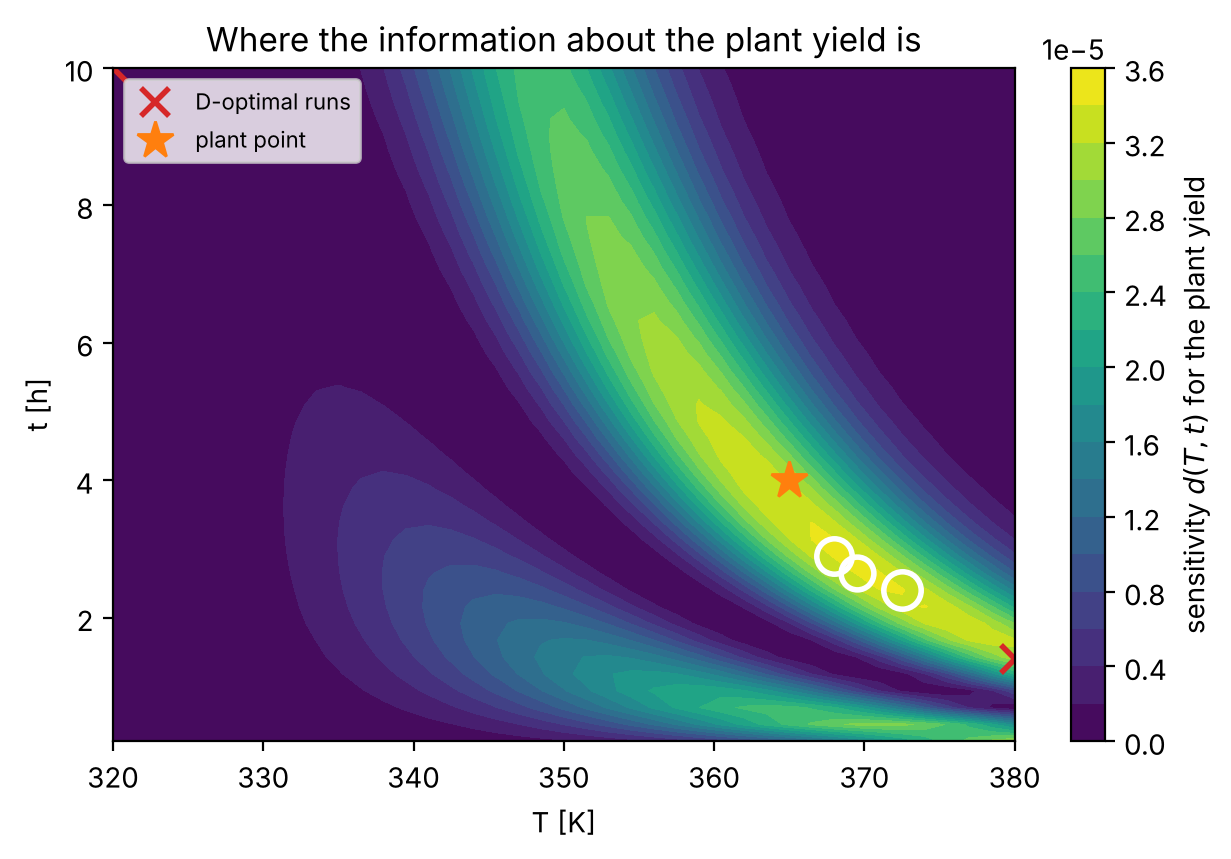

In [5]:
approx = approximate_targeted_design(
    experiment, guess, yield_at_plant, design_bounds=bounds, n_runs=2,
    prior_fim=prior, n_candidates=1681,
)
print(approx.summary())

Ts = np.array([c["T"] for c in approx.candidates])
ts = np.array([c["t"] for c in approx.candidates])
n = int(np.sqrt(len(Ts)))
fig, ax = plt.subplots(figsize=(6.4, 4.4))
cs = ax.contourf(
    Ts.reshape(n, n), ts.reshape(n, n), approx.sensitivity.reshape(n, n), levels=20, cmap="viridis"
)
fig.colorbar(cs, label="sensitivity $d(T, t)$ for the plant yield")
for point, w in approx.support():
    ax.plot(point["T"], point["t"], "o", ms=6 + 20 * w, mfc="none", mec="white", mew=2)
ax.plot(*zip(*[(d["T"], d["t"]) for d in designs["D-optimal"]]), "x", c="tab:red", ms=10, mew=2,
        label="D-optimal runs")
ax.plot(plant["T"], plant["t"], "*", c="tab:orange", ms=14, label="plant point")
ax.set_xlabel("T [K]")
ax.set_ylabel("t [h]")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Where the information about the plant yield is")
plt.tight_layout()

## Several goals, one design: tolerances

Suppose the plant yield is needed to $\pm 0.004$ and $E_2$ to within 2 %, since
$E_2$ sets how much over-reaction a hot spot causes. The two are in different
units, so they are combined through tolerances: weight $1/\tau^2$ on each.
With `"max_variance"` the criterion is then the worst ratio
$\max_j (\sigma_j/\tau_j)^2$: the design works on whichever goal is furthest
from met.

In [6]:
goal = Target.responses(at=[plant], tolerances={"B": 0.004}) + Target.parameters(
    tolerances={"E2": 0.02}, relative=True
)
res = batch_optimal_experiment(
    experiment, guess, bounds, 4, criterion="max_variance", prior_fim=prior, target=goal,
    strategy="joint", n_starts=8,
)
print([(round(d["T"]), round(d["t"], 2)) for d in res.designs])
print(res.target_precision().summary())

cert = certify_design(
    experiment, guess, res.designs, goal, criterion="max_variance",
    design_bounds=bounds, prior_fim=prior, n_candidates=441,
)
print(cert.summary())
weights = np.diag(cert.approximate.dual)
print("dual weight on each goal:", {n: round(float(w), 3) for n, w in zip(cert.approximate.target.names, weights)})

[(377, 1.89), (370, 2.76), (373, 2.3), (355, 6.27)]
Target precision
  SE(B) = 0.00471   σ/τ = 1.18
  SE(E2) = 1.884   σ/τ = 1.18
  all within tolerance: False


design criterion 1.38636; best possible >= 1.37364; certified efficiency >= 99.1%
dual weight on each goal: {'B': 0.941, 'E2': 0.059}


Four runs leave both goals at the same ratio to their tolerance. That is the
minimax criterion at work: it trades one goal against the other until neither
is the bottleneck. They are still above 1, so this budget is not enough for
both goals. The summary shows by how much, before any run is made.

The minimax criterion is not differentiable, but it is still certified. It is
the largest of a family of smooth criteria, so its dual gives a lower bound,
and the dual weights show which goal is actually binding (see
{doc}`../targeted-design`).

## A precision goal and a stopping rule

Now run the campaign. The goal is SE(yield at the plant) $\le 0.004$, one run
at a time, with simulated measurements from the hidden truth. `sequential_doe`
refits after every run, re-resolves the target at the new estimate, and with
`stop_at_tolerance=True` stops as soon as the goal is met. The comparison is
the same loop with D-optimal runs, where we record the yield's precision after
each one. Three noise seeds are shown.

seed     runs to SE <= 0.004


   0  targeted   8   D-optimal   16


   1  targeted   8   D-optimal   16


   2  targeted   8   D-optimal None


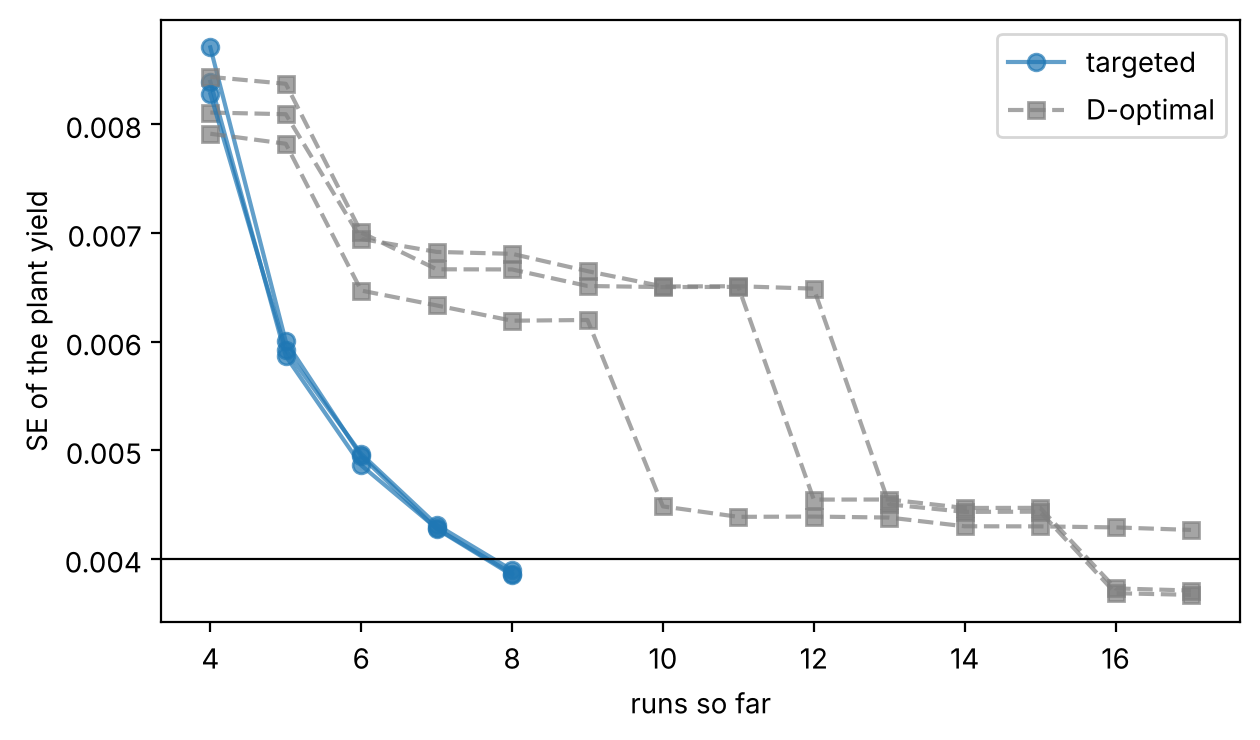

In [7]:
TOL = 0.004
goal_yield = Target.responses(at=[plant], tolerances={"B": TOL})


def campaign(targeted: bool, seed: int, max_runs: int = 18):
    rng = np.random.default_rng(seed)

    def run(design):
        return {"B": model.predict(truth, design) + rng.normal(0.0, 0.01)}

    runs = [dict(d, **run(d)) for d in initial]
    trace = []

    def record(r):
        p = goal_yield.resolve(experiment, r.estimation.parameters).precision(r.estimation.fim)
        trace.append((len(r.runs), p.std["B"]))

    sequential_doe(
        model, None, guess, bounds, initial_runs=runs, n_rounds=max_runs - len(initial),
        run_experiment=run, criterion="trace" if targeted else "determinant",
        target=goal_yield if targeted else None, stop_at_tolerance=targeted, callback=record,
    )
    return trace


fig, ax = plt.subplots(figsize=(6.4, 3.8))
print(f"{'seed':>4s}  {'runs to SE <= 0.004':>22s}")
for seed in range(3):
    tt, dd = campaign(True, seed), campaign(False, seed)
    first = lambda tr: next((n for n, s in tr if s <= TOL), None)  # noqa: E731
    print(f"{seed:>4d}  targeted {first(tt)!s:>3s}   D-optimal {first(dd)!s:>4s}")
    ax.plot(*zip(*[(n, s) for n, s in tt if np.isfinite(s)]), "o-", c="tab:blue", alpha=0.7,
            label="targeted" if seed == 0 else None)
    ax.plot(*zip(*[(n, s) for n, s in dd if np.isfinite(s)]), "s--", c="tab:gray", alpha=0.7,
            label="D-optimal" if seed == 0 else None)
ax.axhline(TOL, c="k", lw=0.8)
ax.set_xlabel("runs so far")
ax.set_ylabel("SE of the plant yield")
ax.legend()
plt.tight_layout()

The targeted campaign reaches the goal in about half the runs. D-optimal runs
also improve the plant prediction, but they spend most of their information on
parameter combinations the plant prediction does not depend on. (`None` means
the goal was not reached within 18 runs.)

## Is the linearized precision honest? A profile-likelihood check

Every number so far, including the stopping rule, comes from the linearized
covariance $K^\top M^{-1} K$ at the current estimate. With few data, or with a
target strongly nonlinear in the parameters, that can understate the real
uncertainty. `profile_target` checks it. For each target it minimizes the
deviance over all parameters subject to $\psi(\theta) = c$, then compares the
resulting interval with $\hat\psi \pm z\,\mathrm{SE}$. Here it is run on the
three screening runs plus the two targeted runs from above, with simulated
data. In the CLI the same check is `discopt doe status --profile`.

In [8]:
rng = np.random.default_rng(0)
five = initial + designs["for plant yield"]
runs = [dict(d, B=model.predict(truth, d) + rng.normal(0.0, 0.01)) for d in five]
camp = campaign_experiment(model, runs)
data = camp.data_from_runs(runs)
estimate = camp.estimate(data, initial_guess=guess)

for target in (
    Target.responses(experiment, at=[plant], responses=["B"]),
    Target.function(t_max, ["t_max"]),
):
    print(profile_target(camp, data, target, model=experiment, initial_estimate=estimate).summary())

Target precision: linearized vs profile likelihood (95% intervals)
  B: 0.12193  linear [0.11028, 0.13359]  profile [0.1104, 0.13372]  -> ok
      the linearized precision matches the profile; tolerance checks are reliable.


Target precision: linearized vs profile likelihood (95% intervals)
  t_max: 1.0652  linear [1.0037, 1.1268]  profile [1.002, 1.126]  -> ok
      the linearized precision matches the profile; tolerance checks are reliable.


With these five runs the linear intervals match the profiles, so the stopping
rule's precision can be trusted. When a target is flagged `CHECK`, the profile
interval is the one to believe, and the design will need more runs than it
predicted.

## When the parameter guess is uncertain

All of the above is *locally* optimal: $K$ and the FIM are evaluated at the
guess. `robust_optimal_experiment` with a target averages the targeted
criterion over parameter samples, here a box of $\pm 0.3$ in $\ln k$ and
$\pm 10$ kJ/mol in $E$. It re-resolves $K$ at every sample, because the plant
prediction's sensitivity moves with the parameters. Using `relative=True`
compares samples on relative precision.

In [9]:
rng = np.random.default_rng(1)
samples = [
    {
        "lnk1": guess["lnk1"] + rng.uniform(-0.3, 0.3),
        "E1": guess["E1"] + rng.uniform(-10, 10),
        "lnk2": guess["lnk2"] + rng.uniform(-0.3, 0.3),
        "E2": guess["E2"] + rng.uniform(-10, 10),
    }
    for _ in range(8)
]
relative_yield = Target.responses(at=[plant], relative=True)
robust = robust_optimal_experiment(
    experiment, samples, bounds, criterion="A", n_experiments=2, prior_fim=prior,
    target=relative_yield, n_starts=6,
)
local = batch_optimal_experiment(
    experiment, guess, bounds, 2, criterion="trace", prior_fim=prior, target=relative_yield,
    strategy="joint",
)


def relative_se(runs):
    out = []
    for s in samples:
        M = prior + sum(compute_fim(experiment, s, d).fim for d in runs)
        out.append(relative_yield.resolve(experiment, s).precision(M).std["B"] / model.predict(s, plant))
    return np.array(out)


for name, runs in (("local", local.designs), ("robust", robust.designs), ("D-optimal", designs["D-optimal"])):
    r = relative_se(runs)
    print(f"{name:>10s}: relative SE over the samples  median {np.median(r):.4f}   worst {r.max():.4f}")

     local: relative SE over the samples  median 0.0456   worst 0.0589
    robust: relative SE over the samples  median 0.0459   worst 0.0590
 D-optimal: relative SE over the samples  median 0.0605   worst 0.0830


For this problem the locally optimal targeted design is already robust over the
uncertainty box: the robust design is nearly the same and does about equally
well at every sample. Both stay well ahead of the D-optimal design at every
sample. When the box is wide enough that the best runs move, the robust design
is the one to use. Use `robust="maximin"` to protect the worst case rather than
the average.

## The same campaign from the command line

`discopt doe new symbolic` takes the same targets as flags, stores them in the
workbook, and reports the predicted precision. `extend` reuses the target, and
`status` reports it against the tolerance after each `fit`.

Here the target is the time of maximum yield at 365 K, written as a formula
(`--target-expr`), to 2 % (`--tolerance` with `--relative-precision`), with no
screening runs yet. Four runs is fewer than the number of parameters, which
the command accepts because only the target has to be identifiable.

For the plant *yield* from scratch, the targeted design is simply to replicate
the plant condition: with no data, the model cannot beat measuring there
directly. The model earns its keep once there are data, as in the sections
above.

In [10]:
discopt = shutil.which("discopt") or str(Path(sys.executable).with_name("discopt"))
k365 = {i: f"exp(lnk{i} - E{i}/{R}*(1/365 - 1/{T_REF}))" for i in (1, 2)}
t_max_formula = f"log({k365[2]}/{k365[1]})/({k365[2]} - {k365[1]})"
cmd = [
    discopt, "doe", "new", "symbolic", "--expr", source,
    "--param", f"lnk1={guess['lnk1']}", "--param", "E1=50", "--param", f"lnk2={guess['lnk2']}",
    "--param", "E2=80", "--input", "T:320:380", "--input", "t:0.2:10", "--response", "B",
    "--error", "0.01", "--n", "4", "--criterion", "trace",
    "--target-expr", f"t_max={t_max_formula}", "--tolerance", "t_max=0.02",
    "--relative-precision", "-o", "kinetics.xlsx", "--force",
]
done = subprocess.run(cmd, capture_output=True, text=True)
print(done.stdout or done.stderr)

created workbook: kinetics.xlsx
  model:         symbolic
  parameters:    4 (lnk1, E1, lnk2, E2)
  criterion:     trace
  target:        t_max (formula)  (tolerances t_max=0.02)  [relative]
  predicted target precision (at the nominal parameters):
           t_max  SE = 0.02525   SE/tolerance = 1
    every target within tolerance: yes
  batch:         1  (run_ids 1-4)
  recommended runs:
    run_id           T           t
         1    366.4856      3.5220
         2    364.8813      3.8510
         3    364.9954      0.6420
         4    363.7038      4.1168
  next:          discopt doe status kinetics.xlsx



In a shell:

```bash
discopt doe new symbolic --expr "$EXPR" --param lnk1=-0.92 --param E1=50 \
    --param lnk2=-1.39 --param E2=80 --input T:320:380 --input t:0.2:10 \
    --response B --error 0.01 --n 4 --criterion trace \
    --target-expr "t_max=$TMAX" --tolerance t_max=0.02 --relative-precision \
    -o kinetics.xlsx
# ... run the experiments, fill in B ...
discopt doe fit kinetics.xlsx
discopt doe status kinetics.xlsx      # SE(B) and SE/tolerance; says when the goal is met
discopt doe extend kinetics.xlsx --n 2   # designed for the stored target
discopt doe extend kinetics.xlsx --n 2 --target-response B@T=365,t=4 --tolerance B=0.004
```

The last line switches the campaign's goal to the plant yield. The new target
replaces the stored one.

## Summary

| You want | Use |
|---|---|
| a prediction at an operating point | `Target.responses(at=[...])`, `"trace"` |
| a derived quantity ($t^*$, a selectivity, a half-life) | `Target.function` / `Target.expression` |
| some parameters, the rest nuisance | `Target.parameters([...])`, `"determinant"` ($D_s$) or `"trace"` |
| several goals in different units | tolerances, then `"trace"` (sum of $(\sigma/\tau)^2$) or `"max_variance"` (worst one) |
| to stop when precise enough | `sequential_doe(..., stop_at_tolerance=True)`, or `discopt doe status` |
| to know how good a design is | `certify_design` (a certified efficiency bound; all four criteria) |
| to check the SE is honest | `profile_target`, or `discopt doe status --profile` |
| protection against a wrong guess | `robust_optimal_experiment(..., target=...)` |

Caveats:

- **Precision is first-order.** It comes from the linearization at the current
  estimate ($\Sigma_\psi = K^\top M^{-1} K$). `profile_target` checks it.
- **Certificates are relative to the candidate grid.** Use a fine grid, or add
  the conditions you care about.
- **Tolerances are judged at the declared measurement error.** That is the
  scale the designs are predicted on.